# 04 — L2 GCOV covariance explorer

**Goal:** understand what the GCOV layers measure.

* GCOV stores the **covariance matrix** of the scattering vector, averaged and geocoded.
  The **diagonal** terms (`HHHH` = ⟨|S_HH|²⟩, `HVHV` = ⟨|S_HV|²⟩) are real backscattered power.
  **Off-diagonal** terms (e.g. `HHHV` = ⟨S_HH S_HV*⟩) are complex and carry the polarimetric phase.
* NISAR GCOV is **radiometrically terrain-corrected**: values are **γ⁰ (gamma-naught)**, normalized by
  the illuminated area computed from a DEM, so slopes facing the radar are not artificially bright.
  `rtcGammaToSigmaFactor` converts to σ⁰ (sigma-naught), the convention of many older studies.
* Values are **linear power**; dB = 10·log10(power).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "04"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
session = P.load_session(kit["session_file"], required=("granule", "frequency"))
src_ctx = lambda: P.open_local_or_remote(session["gcov_local"], session["gcov_url"])

In [2]:
with src_ctx() as h5:
    prof = P.product_profile(h5)
    grid = prof.grids[session["frequency"]]
    # a 2 x 2 km window around the clear-cut site, in the product projection
    from nisar_s1.product import lonlat_to_proj
    cx, cy = 6.7564, 47.9101
    x0, y0, x1, y1 = lonlat_to_proj((cx - 0.013, cy - 0.009, cx + 0.013, cy + 0.009), grid.epsg)
    win = P.window_from_bounds(grid, (x0, y0, x1, y1))
    hh = P.read_layer(h5, grid, "HHHH", win)
    hv = P.read_layer(h5, grid, "HVHV", win)
    g2s = P.read_layer(h5, grid, "rtcGammaToSigmaFactor", win)
    looks = P.read_layer(h5, grid, "numberOfLooks", win)
print("window", win.shape, "pixels; diagonal terms are real:", hh.dtype, hv.dtype)
print("complex off-diagonal terms stored:", prof.complex_terms_available(session["frequency"]))

opening local file: NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5


window (104, 101) pixels; diagonal terms are real: float32 float32
complex off-diagonal terms stored: False


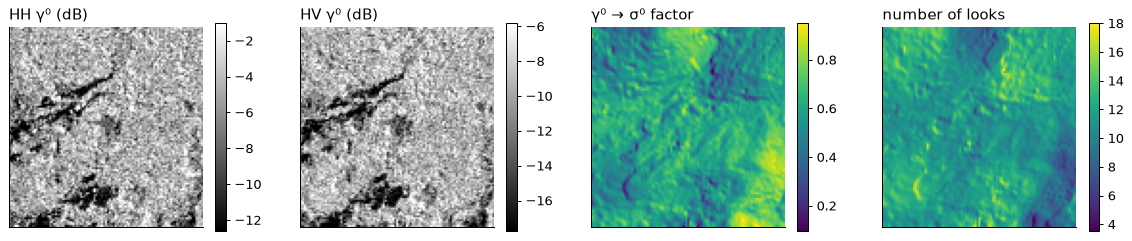

In [3]:
from nisar_s1.polarimetry import to_db
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, (a, t, kw) in zip(axs, [(to_db(hh), "HH γ⁰ (dB)", dict(zip(("vmin", "vmax"), np.nanpercentile(to_db(hh), [2, 98])))),
                                (to_db(hv), "HV γ⁰ (dB)", dict(zip(("vmin", "vmax"), np.nanpercentile(to_db(hv), [2, 98])))),
                                (g2s, "γ⁰ → σ⁰ factor", {}), (looks, "number of looks", {})]):
    im = ax.imshow(a, cmap="gray" if "dB" in t else "viridis", **kw)
    ax.set_title(t, loc="left"); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, shrink=0.75)
fig.savefig(OUT / "04_layers.png", dpi=110, bbox_inches="tight"); plt.show()

## γ⁰ versus σ⁰: same pixels, different normalization

sigma0 - gamma0 (HH): median -2.30 dB, 5-95 % range -4.09 to -1.11 dB


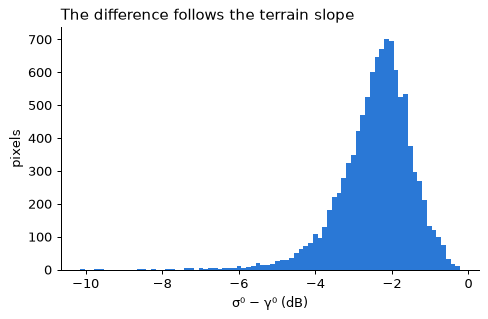

In [4]:
sig_hh = hh * g2s
d = to_db(sig_hh) - to_db(hh)
print(f"sigma0 - gamma0 (HH): median {np.nanmedian(d):+.2f} dB, 5-95 % range "
      f"{np.nanpercentile(d, 5):+.2f} to {np.nanpercentile(d, 95):+.2f} dB")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(d[np.isfinite(d)], bins=80, color="#2a78d6")
ax.set_xlabel("σ⁰ − γ⁰ (dB)"); ax.set_ylabel("pixels"); ax.set_title("The difference follows the terrain slope", loc="left")
plt.show()

## Power statistics
Cross-pol (HV) is typically 6–10 dB below co-pol (HH) over land; at L-band the HV level of forests is
driven by volume scattering in branches and trunks, which is why HV is the classic L-band biomass
and clear-cut indicator.

In [5]:
stats = pd.DataFrame({t: pd.Series(to_db(a)[np.isfinite(a)]).describe(percentiles=[.02, .5, .98])
                      for t, a in {"HH (dB)": hh, "HV (dB)": hv}.items()}).T
stats["HH-HV ratio (dB)"] = np.nan
stats.loc["HH (dB)", "HH-HV ratio (dB)"] = np.nanmedian(to_db(hh) - to_db(hv))
stats.round(2)

,count,mean,std,min,2%,50%,98%,max,HH-HV ratio (dB)
HH (dB),10504.0,-5.43,2.64,-17.75,-12.60,-5.05,-1.01,8.36,4.82
HV (dB),10504.0,-10.24,2.73,-22.82,-17.74,-9.80,-5.80,1.78,NaN


In [6]:
checks = {
    "diagonal terms real-valued": np.isrealobj(hh) and np.isrealobj(hv),
    "HV weaker than HH": np.nanmedian(hv) < np.nanmedian(hh),
    "looks > 1": np.nanmedian(looks) > 1,
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 04 STATUS: PASS")

  [x] diagonal terms real-valued
  [x] HV weaker than HH
  [x] looks > 1
Module 04 STATUS: PASS
